# Example: Compute the Probability of Profit and Terminal Moneyness for a Call Contract
In this example, we'll compute the Probability of Profit (POP) for a __short__ call option contract.

__Scenario:__ Suppose we sold a call option on TSLA. Let's use options data and projections of the TSLA share price to compute the breakeven point for the contract, i.e., the value of the TSLA share price where you (the seller) begin to lose money, the probability of profit (POP), and the probability that the contract finishes in the money.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
>
> * __Calculate breakeven points for call option contracts:__ Compute the share price at expiration where the option position transitions from profit to loss for both buyers and sellers.
> * __Project future share price distributions using two methods:__ Use the GBM model with risk-neutral drift and volatility parameters to generate log-normal distributions, and construct a Normal distribution using implied volatility for quick estimates.
> * __Estimate model-based probability of profit and terminal moneyness:__ Apply the CDF of a stated projected share-price distribution at the breakeven and strike thresholds, and compare these probabilities with Delta without identifying them.

Let's get started!

___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the [Include.jl](Include.jl) file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, [Include.jl](Include.jl), in the notebook's global scope. The [Include.jl](Include.jl) file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/). 

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating 

project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

<div>
    <center>
        <img src="figs/Fig-TSLA-Option-Data-11-3-2025.png" width="800"/>
    </center>
</div>

### Data
Let's set some values for the parameters and constants we will use in this example.

__Data:__ We gathered TSLA contract data at 10:41 am (BOS time) on `11-03-2025`. In this example, we'll use options pricing data for a DTE = 46-day call option on [Tesla](https://finance.yahoo.com/quote/TSLA/) as the underlying asset (ticker `TSLA`), with a strike price of K = 485.0 USD/share. The recorded underlying share price was $S_{0}$ = 471.47 USD/share. The probability of profit for this contract is `70.63%` from the seller's perspective and `29.37%` from the buyer's perspective.

Let's set the parameters for this contract so we can use them below:

We keep the historical screenshot and inputs for this calculation. The displayed broker probability is a comparison value whose model is unspecified; its agreement with our calculation is separate from the numerical checks.

In [2]:
DTE = 46.0; # days to expiration
Sₒ = 471.47; # TSLA underlying share price USD/share
IV = 58.38; # implied volatility
Δt = (1/365); # one calendar day in years
K = 485.0; # strike price for call contract
P = 34.23; # mark premium
B = 519.23; # observed breakeven price for call contract
POP = 0.7063; # probability of profit for short call
risk_free_rate = 0.0431; # retained classroom rate proxy; continuous annual rate
h = 366; # number of levels in the tree

Next, we construct contract models for the options in this example. We begin by building an instance of the [MyAmericanCallContractModel type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.MyAmericanCallContractModel) using the [custom build(...) method for this type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanCallContractModel},%20NamedTuple}). 

The [build(...) method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.build-Tuple{Type{MyAmericanCallContractModel},%20NamedTuple}) takes two arguments: the type of thing we want to build, and a [NamedTuple](https://docs.julialang.org/en/v1/base/base/#Core.NamedTuple) containing the strike price $K$, the premium paid for the option, remaining time `DTE` in years, the `sense` = 1 (long), the number of contracts in the `copy` field and the (decimal) implied volatility (IV) in the `IV` field.

We save the call option contract model in the `call_option_model::MyAmericanCallContractModel` variable:

In [3]:
call_option_model = build(MyAmericanCallContractModel, (
    K = K, 
    premium = P, # mark price
    DTE = (DTE)*Δt,
    sense = 1, # compute greeks of long contract
    copy = 1,
    IV = (IV/100) # must be a decimal
)); # contract variables: accessed at 10:41 am (BOS time) on 11-03-2025

In this example, we'll need to do a projection of the future share price distribution at the contract's expiration date. We'll use a Geometric Brownian Motion (GBM) model to project the future share price distribution at expiration.

Let's load the single asset geometric Brownian motion (SAGBM) parameters which we estimated a few lectures ago, which include the drift and diffusion coefficients for each ticker. We'll store this data in the `parameters_df::DataFrame` variable:

In [4]:
parameters_df = let

    # load -
    df = CSV.read(joinpath(_PATH_TO_DATA,"SAGBM-Parameters-Fall-2025.csv"), DataFrame);
    df; # return
end;

What's in `parameters_df::DataFrame`?

In [5]:
parameters_df

Row,ticker,drift,t,lower_bound_drift,upper_bound_drift,volatility
,String7,Float64,Float64,Float64,Float64,Float64
1,A,0.147468,1.96,0.145161,0.149774,0.231426
2,AAL,-0.141294,1.96,-0.1436,-0.138988,0.454992
3,AAP,-0.0481021,1.96,-0.0504085,-0.0457958,0.342562
4,AAPL,0.24271,1.96,0.240403,0.245016,0.234474
5,ABBV,0.116,1.96,0.113693,0.118306,0.242938
6,ABT,0.123083,1.96,0.120777,0.125389,0.199723
7,ACN,0.151012,1.96,0.148706,0.153319,0.214367
8,ADBE,0.224401,1.96,0.222094,0.226707,0.276273
9,ADI,0.146449,1.96,0.144142,0.148755,0.259329


In [6]:
filter(:ticker=> x-> x=="TSLA", parameters_df)

Row,ticker,drift,t,lower_bound_drift,upper_bound_drift,volatility
,String7,Float64,Float64,Float64,Float64,Float64
1,TSLA,0.356852,1.96,0.354546,0.359158,0.490546


___

## Task 1: Compute the break-even points for long and short TSLA calls
In this task, we'll compute the breakeven price of a short `TSLA` call contract. The breakeven at expiration for both a long or short call contract is the share price $B_{c}(T)$ at expiration such that $P_{c}(K, B_{c}(T)) = 0$. Thus, for our `TSLA` call, the breakeven share price $B_{c}$ USD/share, ignoring fees and financing of the premium, is given by:
$$
\begin{align*}
B_{c} &= K + \mathcal{P}_{c}(K,S(0))
\end{align*}
$$
For the buyer to make money, the share price must be above the breakeven price $B_{c}$. For the seller to make money, the share price must remain below the breakeven price.

`Unhide` the code block below to see how we plotted the profit diagram at expiration for long and short call positions on the `TSLA` contract:

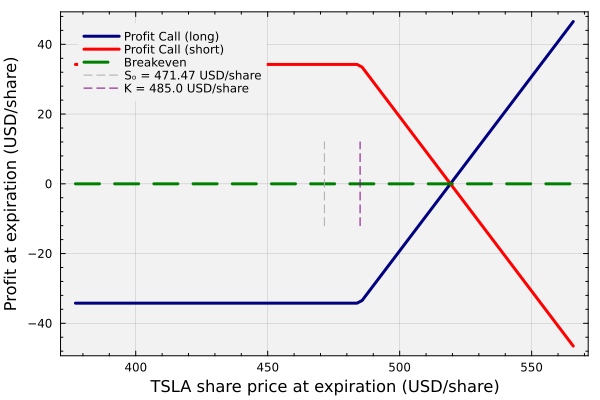

In [7]:
let
    N = 100; # how many points do we want?
    β = range(0.8,stop=1.2, length=N) |> collect;
    ST = Sₒ.*β; # future share price at expiration
    θ = -1; # we are in the short position

    # compute the payoff of the contract -
    payoff_array_long = payoff([call_option_model], ST); # this is always computed for a LONG contract
    profit_array_long = payoff_array_long[:,3] .- P;
    profit_array_short = θ*(payoff_array_long[:,3] .-P);

    # zero line -
    ZL = zeros(N);

    # initial share price line -
    SPL_vertical = range(-12,stop=12,length=N) |> collect;
    SPL_horizontal = Sₒ*ones(N);
    STRIKE_horizontal = K*ones(N);

    # let's visualize
    plot(payoff_array_long[:,1], profit_array_long, c=:navy, lw=3, label="Profit Call (long)", legend=:topleft)
    plot!(payoff_array_long[:,1], profit_array_short, c=:red, lw=3, label="Profit Call (short)")
    plot!(payoff_array_long[:,1],ZL, c=:green, lw=3, ls=:dash, label="Breakeven")
    plot!(SPL_horizontal, SPL_vertical, lw=1,c=:gray67,ls=:dash, label="Sₒ = $(Sₒ) USD/share")
    plot!(STRIKE_horizontal, SPL_vertical, lw=1,c=:purple,ls=:dash, label="K = $(K) USD/share")
    xlabel!("TSLA share price at expiration (USD/share)", fontsize=18)
    ylabel!("Profit at expiration (USD/share)", fontsize=18)
    plot!(bg="gray95", background_color_outside="white", framestyle = :box, 
        fg_legend = :transparent, xminorticks = true, yminorticks = true);
end

Compute the break-even price for the call contract and store this in the `computed_breakeven_price::Float64` variable:

In [8]:
computed_breakeven_price = K + P

519.23

### Check: Are the computed and observed breakeven points equal?
The breakeven share price was reported in the dataset: ${B}_{c}=$ `519.23 USD/share`. Confirm the `computed_breakeven_price` by comparing this value with the reported value using the [Julia @assert macro](https://docs.julialang.org/en/v1/base/base/#Base.@assert) in combination with the [Julia isapprox(...) function](https://docs.julialang.org/en/v1/base/math/#Base.isapprox).

> __Test:__ If the observed and `computed_breakeven_price` are _not_ approximately equal to some relative tolerance (specified in the `rtol` argument), then an [AssertionError](https://docs.julialang.org/en/v1/base/base/#Core.AssertionError) is thrown.

So what do we get?

In [9]:
let
    println("Reported breakeven: ",B," USD/share; computed: ",computed_breakeven_price," USD/share")

    # checks -
    @assert isapprox(B,computed_breakeven_price;atol=1e-10)

    # return -
    nothing
end

Reported breakeven: 519.23 USD/share; computed: 519.23 USD/share


___

## Task 2: Construct a single asset GBM model of TSLA share price
In this task, we'll use geometric Brownian motion to compute the distribution of future share prices at expiration $S(T)$ of the call contract. Despite a few shortcomings, a nice feature of geometric Brownian motion is that it has a convenient analytical solution:
$$
\begin{equation*}
S_{t} = S_{0}\;\exp\Biggl[\left(\mu-\frac{\sigma^{2}}{2}\right)\left(t - t_{0}\right) + (\sigma\sqrt{t-t_{0}})\;{Z_{t}(0,1)}\Biggr]
\end{equation*}
$$
where $S_{0}$ is the initial share price at $t_{0}$, and $Z_{t}(0,1)$ is a standard normal random variable drawn at time $t$. Geometric Brownian motion will produce a future share price distribution that follows a log-normal distribution, with expectation and variance given by:
$$
\begin{align*}
\mathbb{E}\left(S_{t}\right) &= S_{0}\;\exp\left(\mu(t-t_{0})\right)\\
\text{Var}\left(S_{t}\right) &= S_{0}^{2}e^{2\mu\cdot(t-t_{0})}\left[e^{\sigma^{2}(t-t_{0})} - 1\right]
\end{align*}
$$
where $(t-t_{0})$ is the time interval. We'll use the analytical solution to compute the distribution of share price values at $t = T$, i.e., at the contract's expiration.

The same solution specifies the terminal distribution directly. We will compare a seeded simulation and its fitted density with this analytic distribution, then use the analytic CDF for all probability calculations.

Next, we'll build an instance of the [MyGeometricBrownianMotionEquityModel type](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.MyGeometricBrownianMotionEquityModel) holding drift `μ` and volatility `σ`. We retain three classroom scenarios: risk-free drift with the smaller volatility estimate, risk-free drift with the larger estimate, and historical drift with the larger estimate. Case 2 is selected initially.

We select the TSLA row with the [filter(...) function](https://dataframes.juliadata.org/stable/lib/functions/#Base.filter) and read its historical drift and volatility. The selected volatility is the maximum of the implied and historical estimates, so the printed model inputs identify which value enters the calculation. Risk-free drift defines a pricing-measure scenario under our zero-dividend assumptions; historical drift defines a separate projection whose forecast accuracy needs its own evidence.

Let's save the selected model and print its parameters:

In [10]:
scenario = 2; # change to 1 or 3 to explore the retained alternatives
model = let
    row = first(filter(:ticker => ==("TSLA"),parameters_df));
    small_vol=min(IV/100,row.volatility);
    large_vol=max(IV/100,row.volatility);
    cases=((μ=risk_free_rate,σ=small_vol),(μ=risk_free_rate,σ=large_vol),(μ=row.drift,σ=large_vol));
    selected=cases[scenario];
    println("Scenario ",scenario,": drift = ",selected.μ," per year; volatility = ",selected.σ)

    # return -
    build(MyGeometricBrownianMotionEquityModel,selected)
end;

Scenario 2

: drift = 0.0431 per year; volatility = 0.5838


Now that we have a populated [MyGeometricBrownianMotionEquityModel instance](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.MyGeometricBrownianMotionEquityModel) holding the `TSLA` data, let's generate `number_of_samples` possible future share price values using the [sample(...) function exported by the VLQuantitativeFinancePackage.jl package](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}).
* The [sample method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}) takes a `model::MyGeometricBrownianMotionEquityModel` instance as the first argument, along with the time values that we wish to sample: `T₁::Float64` is the start time, `T₂::Float64` is the stop-time (in units of `years`), `Δt::Float64` is the time step (in units of `years`), and `Sₒ::Float64` denotes the initial share price (in units of `USD/share`). Finally, we pass in the number of samples we want to generate in the `number_of_paths` argument.
* The [sample method](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/equity/#VLQuantitativeFinancePackage.sample-Tuple{MyMultipleAssetGeometricBrownianMotionEquityModel,%20NamedTuple}) generates `number_of_paths` sample paths from $T_{1}\rightarrow{T}_{2}$ in steps of $\Delta{t}$. However, we only want the share prices corresponding to the duration of the contract, i.e., $T_{2} = \text{DTE}$. Thus, we pass the full `samples` array [using the Julia pipe operator](https://docs.julialang.org/en/v1/manual/functions/#Function-composition-and-piping) to a slicing operation where we select columns `2:end` of the last row (col 1 holds the time). We store the `number_of_paths` samples of the share price at $T_{2}$ in the `endpoint::Array{Float64,1}` variable.

So what do we get?

In [11]:
endpoint_samples = let

    # initialize
    Random.seed!(566010); # reproduce this simulation when rerunning the selected scenario
    number_of_samples = 50000; # how many samples do we want to generate?

    # compute the endpoint samples -
    endpoint = VLQuantitativeFinancePackage.sample(model, (
        T₁ = 0.0,
        T₂ = (DTE)*(Δt),
        Δt = Δt,
        Sₒ = Sₒ
    ), number_of_paths = number_of_samples) |> samples -> samples[end,2:end]; # get last row from col 2 -> number_of_paths

    # return -
    endpoint;
end

50000-element Vector{Float64}:
 465.38058479541155
 592.0498591398317
 454.1436282351277
 449.30240516862904
 580.6705386972857
 517.1925196003057
 390.8673353319538
 648.6512874959038
 542.4739521434128
 544.5684679217801
 536.0293817147285
 557.0337133935528
 459.3616350565263
   ⋮
 404.52444337948344
 491.11225969699365
 554.5178244091526
 437.64438888821763
 366.5750251912614
 523.7021637240081
 431.0369694086071
 388.37542730309286
 417.80479843500217
 657.6999831847882
 436.71700652364854
 517.3708248087269

### Check: Do simulated endpoints match the analytic distribution?
The analytic GBM solution determines the location and scale of the logarithm of the terminal price. For remaining time $\tau=\mathrm{DTE}/365$ in years, the distribution is:

$$
S(T)\sim\operatorname{LogNormal}\!\left(\ln S_0+(\mu-\sigma^2/2)\tau,\;\sigma\sqrt\tau\right).
$$

The second argument is the standard deviation of the log price. Let's construct this [LogNormal distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.LogNormal) as `d_gbm` and also retain the [maximum-likelihood fit](https://juliastats.org/Distributions.jl/stable/fit/#Distributions.fit_mle) as `d_fitted` for a visual comparison.

In [12]:
τ = DTE*Δt; # remaining time in years
d_gbm = LogNormal(log(Sₒ)+(model.μ-model.σ^2/2)*τ,model.σ*sqrt(τ));
d_fitted = fit_mle(LogNormal,endpoint_samples);

The [one-sample Kolmogorov–Smirnov test](https://juliastats.org/HypothesisTests.jl/stable/nonparametric/#Kolmogorov-Smirnov-test) compares the simulated endpoints with the analytic distribution whose parameters were specified before sampling. Its p-value measures evidence against that specified distribution; failure to reject leaves the model compatible with this sample.

We use the analytic distribution for the test because estimating its parameters from the same observations changes the reference distribution of the test statistic. See the [standard KS-test assumptions](https://www.stat.ethz.ch/R-manual/R-devel/library/stats/html/ks.test.html).

In [13]:
test_result = ExactOneSampleKSTest(endpoint_samples, d_gbm)

Exact one sample Kolmogorov-Smirnov test
----------------------------------------
Population details:
    parameter of interest:   Supremum of CDF differences
    value under h_0:         0.0
    point estimate:          0.0036238

Test summary:
    outcome with 95% confidence: fail to reject h_0
    two-sided p-value:           0.5275

Details:
    number of observations:   50000


In [14]:
let
    empirical=mean(endpoint_samples .<= B);
    analytic=cdf(d_gbm,B);
    standard_error=sqrt(analytic*(1-analytic)/length(endpoint_samples));
    println("KS p-value against the specified analytic distribution: ",pvalue(test_result))
    println("Simulated seller POP: ",empirical,"; analytic seller POP: ",analytic)
    println("Difference / Monte Carlo standard error: ",(empirical-analytic)/standard_error)

    # checks -
    @assert abs(empirical-analytic) <= 5*standard_error

    # return -
    nothing
end

KS p-value against the specified analytic distribution: 0.5274679747004808
Simulated seller POP: 0.70734; analytic seller POP: 0.7064332648977102
Difference / Monte Carlo standard error: 0.44522181820771617


Let's plot the simulated endpoint density, the analytic GBM density, and the fitted LogNormal density. Agreement here checks the implementation of the stated model; the market forecast depends on the choice of drift and volatility.

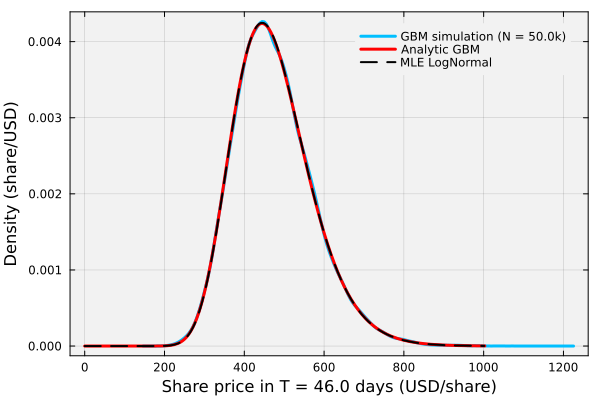

In [15]:
let
    density(endpoint_samples, lw=3, c=:deepskyblue1, label="GBM simulation (N = $(length(endpoint_samples)/1000)k)")
    plot!(d_gbm, lw=3, label="Analytic GBM", c=:red, 
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent)
    plot!(d_fitted;lw=2,linestyle=:dash,label="MLE LogNormal",c=:black)
    xlabel!("Share price in T = $(DTE) days (USD/share)", fontsize=18)
    ylabel!("Density (share/USD)", fontsize=18)
end

### Alternative: Future share price projection using implied volatility
Alternatively, we could use the __implied volatility__ to estimate the expected share price move over some time $0\rightarrow{T}$.
Suppose we construct a [Normal distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal) $\mathcal{N}(\mu_{IV},\sigma_{IV})$ where remaining time is $\tau=\mathrm{DTE}/365$ in years and the mean $\mu_{IV} = S_{0}\exp(r\tau)$, i.e., the risk-neutral future value of the current share price, or just $\mu_{IV}\approx{S}_{0}$ for short duration contracts, and the standard deviation $\sigma_{IV}$ is given by:

$$
\sigma_{IV} = S_{0}\cdot\left(\frac{\text{IV}}{100}\right)\cdot\sqrt{\tau}
$$
using the [Normal type exported by the Distributions.jl package](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal). This is only an approximate model of the future share price; it has a couple of issues: 
> __Watch out!__ This model assumes a [Normal distribution](https://juliastats.org/Distributions.jl/stable/univariate/#Distributions.Normal), which is problematic because it can emit negative share prices. One way to fix this issue is to use a [Truncated Normal distribution](https://juliastats.org/Distributions.jl/stable/truncate/#Truncated-Distributions) instead.

However, despite the potential issues, this model is used to generate quick estimates of future share price ranges using the forward-looking implied volatility. Let's save the Normal IV distribution $\mathcal{N}(\mu_{IV},\sigma_{IV})$ in the `d_IV` variable:

In [16]:
d_IV = Normal(Sₒ*exp(risk_free_rate*DTE*Δt), Sₒ*(IV/100)*sqrt(DTE*Δt));

`Unhide` the code block below to see how we plotted the `d_gbm` and `d_IV` future share price densities at `T = 46 days`.  

> __What do we see?__ The log-normal GBM share price distribution (blue line) is right-skewed and cannot admit negative share prices. However, the Normal IV distribution (red line) is symmetric around the risk-free forward price $S_0 e^{r\tau}$ and can admit negative share prices, albeit with a small probability.

How do the two distributions compare?

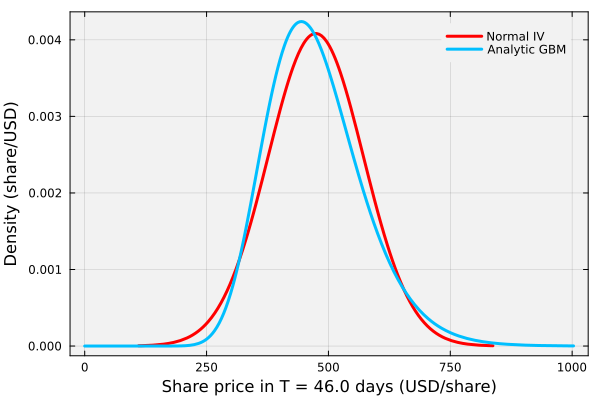

In [17]:
let
    plot(d_IV, lw=3, label="Normal IV", c=:red, 
        bg="gray95", background_color_outside="white", framestyle = :box, fg_legend = :transparent)
    plot!(d_gbm, lw=3, label="Analytic GBM", c=:deepskyblue1)
    
    xlabel!("Share price in T = $(DTE) days (USD/share)", fontsize=18)
    ylabel!("Density (share/USD)", fontsize=18)
end

___

## Task 3: Estimate Probability of Profit and Terminal Moneyness for a TSLA call contract
In this task, we calculate the probabilities of profit and terminal moneyness from the stated distributions, then compare terminal moneyness with Delta.

> __Probability of Profit (POP)__
>
> Given the ability to simulate future share price distributions, we can now compute the likelihood of seeing a particular range of values. Let's consider this contract from the buyer's and seller's perspectives:
> * __Buyer's perspective__: the `TSLA` share price `T` days from now $S(T)$, must be _greater than_ the breakeven price $B_{c}$ for the `call` contract to be profitable. The probability of profit can be calculated from the [cumulative distribution function of the share price](https://en.wikipedia.org/wiki/Cumulative_distribution_function), i.e., $P(S_{T}>{B}_{c}) = 1 - F_{S}(B_{c})$ where $F_{S}(B_{c})$ is the cumulative distribution function evaluated at the breakeven price.
> * __Seller's perspective__: the `TSLA` share price `T` days from now $S(T)$, must be _less than_ the breakeven price $B_{c}$ for the `call` contract to be profitable. The probability of profit can be calculated from the [cumulative distribution function of the share price](https://en.wikipedia.org/wiki/Cumulative_distribution_function), i.e., $P(S_{T}\leq{B}_{c}) = F_{S}(B_{c})$.

We can query the [cumulative distribution function $F_{S}(B_{\star})$](https://en.wikipedia.org/wiki/Cumulative_distribution_function) for the projected geometric Brownian motion distribution `d_gbm` using the [cdf(...) function exported by the Distributions.jl package](https://github.com/JuliaStats/Distributions.jl?tab=readme-ov-file).

### Compare the probability models
Let's keep the historical broker probabilities alongside the analytic GBM and Normal-IV calculations. Their differences reflect the stated distributional choices and the unspecified broker model. The numerical checks verify probability bounds and buyer/seller complements; market agreement is reported as a comparison.

In [18]:
probability_table = let
    table=DataFrame();
    for (name,distribution) in (("Analytic GBM",d_gbm),("Normal IV",d_IV))
        buyer=ccdf(distribution,B);
        seller=cdf(distribution,B);
        push!(table,(model=name,buyer_POP=buyer,seller_POP=seller,
            seller_difference_pp=100*(seller-POP)));
    end
    push!(table,(model="Historical broker quote",buyer_POP=1-POP,seller_POP=POP,seller_difference_pp=0.0));
    pretty_table(table;fit_table_in_display_horizontally=false);

    # checks -
    @assert all(0 .<= table.buyer_POP .<= 1)
    @assert all(0 .<= table.seller_POP .<= 1)
    @assert all(isapprox.(table.buyer_POP.+table.seller_POP,1.0;atol=1e-12))

    # return -
    table
end;

┌─────────────────────────┬───────────┬────────────┬──────────────────────┐
│                   model │ buyer_POP │ seller_POP │ seller_difference_pp │
│                  String │   Float64 │    Float64 │              Float64 │
├─────────────────────────┼───────────┼────────────┼──────────────────────┤
│            Analytic GBM │  0.293567 │   0.706433 │            0.0133265 │
│               Normal IV │  0.321861 │   0.678139 │             -2.81613 │
│ Historical broker quote │    0.2937 │     0.7063 │                  0.0 │
└─────────────────────────┴───────────┴────────────┴──────────────────────┘


### Terminal moneyness probability and Delta
We know that $\Delta$ measures the local rate of change in the option premium $\mathcal{P}_{\tau}$ with respect to a `+1 USD/share` change in the underlying asset's price. Traders sometimes compare Delta with terminal moneyness probability, but they are different mathematical objects. Let's quantify the difference.

> __Delta probability heuristic__: Market practice commonly uses call Delta as an approximate implied probability of expiring ITM and $1-\Delta$ as the approximate probability of expiring OTM. This is a useful heuristic, not an exact identity: in the European Black--Scholes model, call Delta is $N(d_1)$ while the risk-neutral ITM probability is $N(d_2)$. For an American option, actual early exercise or assignment is more complicated than terminal moneyness.

Let's explore this idea with our `TSLA` call options by computing Delta.
* We estimate $\Delta$ using the [delta(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.delta). The [delta(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/derivatives/#VLQuantitativeFinancePackage.delta) takes several arguments: the `call_option_model` instance and parameters used to compute the risk-neutral binomial share price tree, e.g., the number of tree levels `h`, the current share price `Sₒ`, the number of days to expiration `T`, etc., and returns the estimated value for Delta.

We store the estimated value for Delta in the `delta_long_call::Float64` variable.

In [19]:
delta_long_call = let

    # initialize
    greek_value = 0.0; # initially set the greek value to 0
    contract_model = call_option_model; # alias the contract model

    # call the greek function
    greek_value = delta(contract_model, h = h,  T = contract_model.DTE, 
        σ = contract_model.IV, Sₒ = Sₒ, μ = risk_free_rate);

    # return -
    greek_value;
end

0.4899999999999949

The computed value means that the option premium changes locally by about 0.49 USD/share for a 1 USD/share spot increase, holding the model's other inputs fixed. It does not by itself assert a 49% terminal ITM probability.

__From the buyer's perspective:__ The buyer needs the share price to be $S_{T} > K+\epsilon$ where $\epsilon > 0$ at expiration to have a __non-zero intrinsic (exercise) value__. Let's use $\epsilon=$ `0.01` USD/share. The probability of this case is given by: $P(S_{T}>(K+\epsilon)) = 1 - F_{S}(K+\epsilon)$.

In [20]:
1 - cdf(d_gbm, K+(1/100)) # terminal ITM probability under the selected GBM distribution

0.4152603030871179

__From the seller's perspective:__ The seller wants the option to expire out of the money (OTM), i.e., the seller gets to keep all the premium paid by the buyer. Thus, the seller wants $S_{T} \leq K$. The probability of this case is given by $P(S_{T} \leq K) = F_{S}(K)$:

In [21]:
cdf(d_gbm, K)

0.5847009065117175

__Use the complement correctly:__ Under the Delta heuristic, $\Delta$ approximates the call's ITM probability and $1-\Delta$ approximates its OTM probability—the outcome favorable to the short seller. The short seller's assignment event corresponds to the same ITM event as the long holder's exercise event, so $1-\Delta$ should not be labeled the seller's probability of exercise. Compare both heuristics with the CDF-based probabilities.

In [22]:
let
    terminal_ITM_probability=ccdf(d_gbm,K);
    terminal_OTM_probability=cdf(d_gbm,K);
    d2=(log(Sₒ/K)+(model.μ-model.σ^2/2)*τ)/(model.σ*sqrt(τ));
    analytic_normal_tail=cdf(Normal(),d2);
    println("Delta heuristic for terminal ITM: ",round(100*delta_long_call;digits=2),"%")
    println("1 - Delta heuristic for terminal OTM: ",round(100*(1-delta_long_call);digits=2),"%")
    println("GBM terminal ITM probability: ",round(100*terminal_ITM_probability;digits=2),"%")
    println("GBM terminal OTM probability: ",round(100*terminal_OTM_probability;digits=2),"%")

    # checks -
    @assert isapprox(terminal_ITM_probability+terminal_OTM_probability,1.0;atol=1e-12)
    @assert isapprox(terminal_ITM_probability,analytic_normal_tail;atol=1e-12)

    # return -
    nothing
end

Delta heuristic for terminal ITM: 49.0%
1 - Delta heuristic for terminal OTM: 51.0%
GBM terminal ITM probability: 41.53%
GBM terminal OTM probability: 58.47%


___

## Summary
We computed the call's breakeven price, checked simulated prices against the analytic GBM endpoint distribution, and compared model-based probabilities with a historical quote and Delta.

> __Key Takeaways:__
>
> * __The threshold determines the event:__ We used the breakeven share price for profit and the strike for terminal moneyness. A call can finish in the money while its buyer still loses money after paying the premium.
> * __Distributional assumptions change the probability:__ We specified drift and volatility, compared the analytic LogNormal and approximate Normal projections, and kept the broker quote as a separate comparison. Risk-free drift and historical drift answer different modeling questions.
> * __Numerical validation differs from forecast validation:__ We checked a reproducible simulation against a distribution specified before sampling and verified complementary probabilities. Delta supplied local exposure, while terminal probability came from the selected distribution.

The selected scenario changes the probabilities. Repeat the same checks when exploring the alternative drift and volatility inputs.

___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team. 

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___